# Phân tích dữ liệu chuyên sâu (Train-Only) & Khai thác hệ luật — Medical Expert System

Notebook này tái lập toàn bộ bằng chứng phân tích dữ liệu (EDA), kiểm định tương quan đơn biến/đa biến, phân tích lỗi ngoài fold (OOF) và đối chứng hệ luật trên **5-fold Cross-Validation** cho cả 4 tập dữ liệu (**Cleveland, Pima, ILPD, CKD**).

> **Nguyên tắc chống rò rỉ dữ liệu (`AGENTS.md`):**
> - Toàn bộ tính toán chỉ đọc **tập huấn luyện (`train_ids`)** và **dự đoán ngoài fold (OOF validation)** trong `results/t06-cv-seed42`.
> - Tập holdout (`test_ids` và `results/t10-test-seed42`) **tuyệt đối không được nạp hay kiểm tra** trong notebook này.
>
> **Yêu cầu môi trường (Local Python `.venv`):** Notebook sử dụng `numpy`, `pandas`, `matplotlib` (và `ipykernel` để chạy trong Jupyter/VS Code). Nếu kernel chưa cài `pandas`/`matplotlib`, cài vào `.venv` theo hướng dẫn của dự án trước khi chạy.

,dataset,n_train,n_pos,n_neg,pos_rate_%,selected_ml,train_medians,source_missing
0,Cleveland (Tim mạch),242,111,131,45.9,gaussian_nb,"age=55.0, bp=130.0, chol=243.0",0
1,Pima (Tiểu đường),614,214,400,34.9,knn,"glucose=118.0, bmi=32.3, age=29.0","glucose:5, bmi:11"
2,ILPD (Gan),456,325,131,71.3,logistic,"bilirubin=1.0, albumin=3.1, age=45.0",0
3,CKD (Thận),320,200,120,62.5,tree,"creatinine=1.3, bp=80.0, age=54.0","creatinine:17, bp:12, age:9"


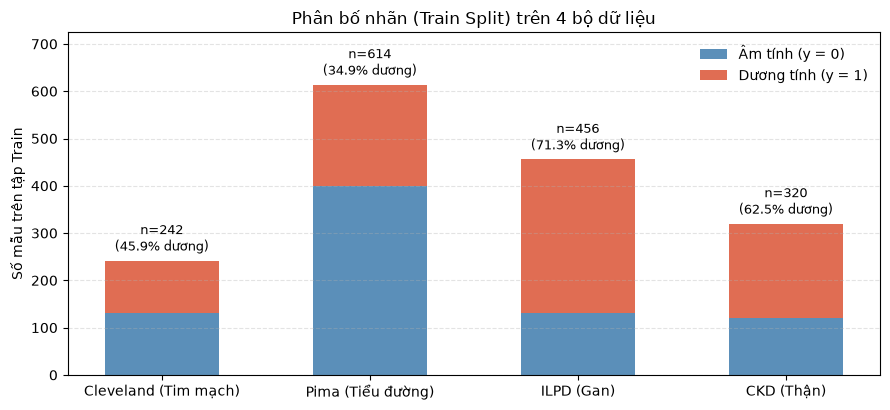

In [1]:
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Định vị thư mục gốc repo (hỗ trợ chạy từ gốc repo hoặc từ notebooks/)
ROOT = Path.cwd().resolve()
if not (ROOT / "medical_expert").is_dir() and (ROOT.parent / "medical_expert").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from medical_expert.expert.fuzzy import fuzzy_membership
from medical_expert.expert.fusion import fusion_scores
from medical_expert.expert.rules import evaluate_rules
from medical_expert.ml.metrics import aggregate_metrics, binary_metrics

RUN_DIR = ROOT / "results" / "t06-cv-seed42"
state = json.loads((RUN_DIR / "models.json").read_text(encoding="utf-8"))
meta = json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8"))
manifest = json.loads((RUN_DIR / "split_manifest.json").read_text(encoding="utf-8"))

# Nạp dự đoán ngoài fold (OOF validation) của mô hình ML đã chọn cho từng bộ
oof_selected = {}
with (RUN_DIR / "predictions.csv").open(encoding="utf-8") as f:
    for row in csv.DictReader(f):
        ds = row["dataset"]
        if row["experiment"] == "ml" and row["variant"] == state["datasets"][ds]["selected"]:
            oof_selected.setdefault(ds, {})[row["sample_id"]] = (
                int(row["y_true"]),
                int(row["y_pred"]),
                float(row["score"]),
            )

DATASETS = ("cleveland", "pima", "ilpd", "ckd")
DATASET_LABELS = {
    "cleveland": "Cleveland (Tim mạch)",
    "pima": "Pima (Tiểu đường)",
    "ilpd": "ILPD (Gan)",
    "ckd": "CKD (Thận)",
}
DATASET_COLORS = {
    "cleveland": "#d95f02",
    "pima": "#1b9e77",
    "ilpd": "#7570b3",
    "ckd": "#e7298a",
}

# Tái dựng DataFrame tập train (đảo chuẩn hóa từ ma trận train KNN đã lưu trong models.json)
train_dfs = {}
overview_rows = []
for ds in DATASETS:
    entry = state["datasets"][ds]
    feats = entry["feature_order"]
    means = np.array(entry["preprocessor"]["means"], dtype=float)
    scales = np.array(entry["preprocessor"]["scales"], dtype=float)
    medians = np.array(entry["preprocessor"]["medians"], dtype=float)
    X_raw = np.array(entry["models"]["knn"]["X"], dtype=float) * scales + means
    y = np.array(entry["models"]["knn"]["y"], dtype=int)
    train_ids = manifest[ds]["train_ids"]

    assert len(train_ids) == len(y), f"Mismatch train_ids vs y for {ds}"
    assert all(oof_selected[ds][sid][0] == y[i] for i, sid in enumerate(train_ids)), f"OOF alignment failed for {ds}"

    df = pd.DataFrame(X_raw, columns=feats)
    df.insert(0, "sample_id", train_ids)
    df["y"] = y
    df["ml_score_oof"] = [oof_selected[ds][sid][2] for sid in train_ids]
    df["ml_pred_oof"] = (df["ml_score_oof"] >= 0.5).astype(int)
    train_dfs[ds] = df

    src_miss = meta["datasets"][ds]["source_metadata"]["missing_by_feature"]
    overview_rows.append({
        "dataset": DATASET_LABELS[ds],
        "n_train": len(y),
        "n_pos": int(y.sum()),
        "n_neg": int((1 - y).sum()),
        "pos_rate_%": round(100 * y.mean(), 1),
        "selected_ml": entry["selected"],
        "train_medians": ", ".join(f"{f}={m:.1f}" for f, m in zip(feats, medians)),
        "source_missing": ", ".join(f"{k}:{v}" for k, v in src_miss.items() if v > 0) or "0",
    })

overview_df = pd.DataFrame(overview_rows)
display(overview_df)

# Biểu đồ tỷ lệ lớp dương / âm trên tập train của 4 bộ dữ liệu
fig, ax = plt.subplots(figsize=(9, 4.2))
x_pos = np.arange(len(DATASETS))
neg_counts = [int((train_dfs[ds]["y"] == 0).sum()) for ds in DATASETS]
pos_counts = [int((train_dfs[ds]["y"] == 1).sum()) for ds in DATASETS]

ax.bar(x_pos, neg_counts, width=0.55, label="Âm tính (y = 0)", color="#5b8fb9")
ax.bar(x_pos, pos_counts, width=0.55, bottom=neg_counts, label="Dương tính (y = 1)", color="#e06d53")
for i, ds in enumerate(DATASETS):
    total = neg_counts[i] + pos_counts[i]
    rate = 100 * pos_counts[i] / total
    ax.text(i, total + 12, f"n={total}\n({rate:.1f}% dương)", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x_pos)
ax.set_xticklabels([DATASET_LABELS[ds] for ds in DATASETS])
ax.set_ylabel("Số mẫu trên tập Train")
ax.set_title("Phân bố nhãn (Train Split) trên 4 bộ dữ liệu")
ax.set_ylim(0, max(n + p for n, p in zip(neg_counts, pos_counts)) * 1.18)
ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Nhận xét phần 1 — Cấu trúc dữ liệu, cân bằng lớp & dữ kiện thiếu

- **Mất cân bằng lớp rõ rệt trên ILPD ($71{,}3\%$ dương) và CKD ($62{,}5\%$ dương):** Đây là nguyên nhân trực tiếp khiến Logistic Regression trên ILPD có `bias` dương lớn và dễ báo dương giả (FP). Ngược lại, Pima có tỷ lệ dương thấp hơn ($34{,}9\%$), còn Cleveland khá cân bằng ($45{,}9\%$).
- **Trung vị `bp = 80 mmHg` ở CKD:** Giải thích vì sao miền nhập cũ `[90, 200]` của form CKD làm lệch hoàn toàn suy luận GUI (`247/320` mẫu train có `bp < 90`), và xác nhận việc mở miền nhập về `[50, 200]` (mặc định `80`) là bắt buộc.
- **Lưu ý về dữ liệu thiếu:** Ma trận train trích từ artifact KNN đã điền trung vị tại các ô thiếu (`glucose: 5`, `bmi: 11` ở Pima; `creatinine: 17`, `bp: 12`, `age: 9` ở CKD trên toàn bộ nguồn), khớp hoàn toàn với nhãn trong `predictions.csv` (`assert` đạt 100%).

---

## 2. Sức mạnh phân tách đơn biến (ROC-AUC, Spearman & Phân vị theo lớp)

,dataset,feature,roc_auc,direction,separation_|AUC-0.5|,spearman,y0_median,y1_median,min,max
0,ckd,creatinine,0.931,tăng (+),0.431,0.723,0.9,2.20,0.4,76.0
1,pima,glucose,0.805,tăng (+),0.305,0.504,107.0,141.00,44.0,199.0
2,ilpd,bilirubin,0.690,tăng (+),0.190,0.299,0.8,1.40,0.4,75.0
3,pima,age,0.680,tăng (+),0.180,0.297,27.0,35.00,21.0,81.0
4,pima,bmi,0.680,tăng (+),0.180,0.297,30.1,34.25,18.2,67.1
5,ckd,bp,0.670,tăng (+),0.170,0.295,70.0,80.00,50.0,180.0
6,ckd,age,0.663,tăng (+),0.163,0.274,45.5,58.50,2.0,90.0
7,cleveland,age,0.649,tăng (+),0.149,0.258,52.0,58.00,29.0,77.0
8,ilpd,albumin,0.378,nghịch (−),0.122,-0.192,3.5,3.00,0.9,5.5
9,cleveland,bp,0.607,tăng (+),0.107,0.185,130.0,132.00,94.0,200.0


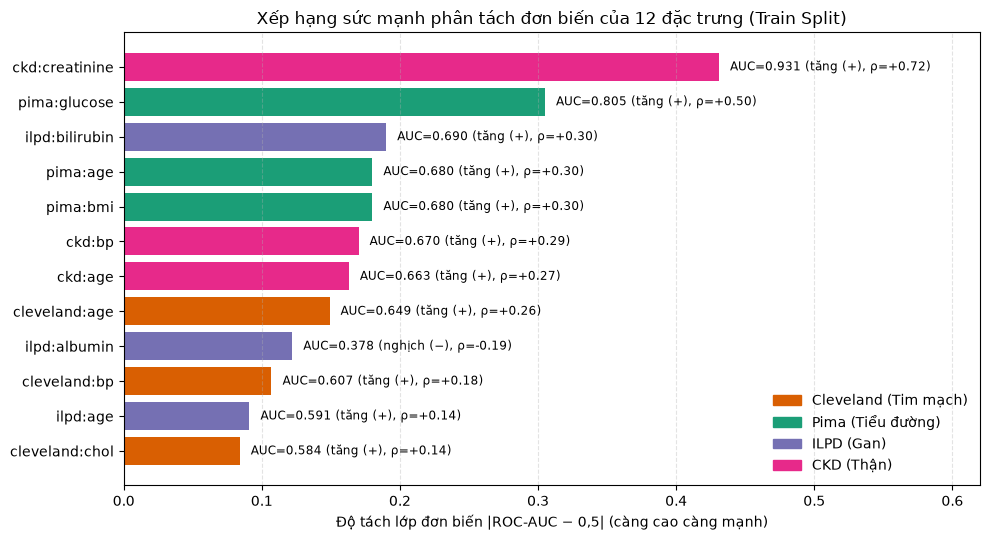

In [2]:
def spearman_corr(x, y):
    rx = pd.Series(x).rank().to_numpy(dtype=float)
    ry = pd.Series(y).rank().to_numpy(dtype=float)
    return float(np.corrcoef(rx, ry)[0, 1])

univariate_rows = []
for ds in DATASETS:
    df = train_dfs[ds]
    feats = state["datasets"][ds]["feature_order"]
    y = df["y"].to_numpy()
    for feat in feats:
        col = df[feat].to_numpy()
        m, _ = binary_metrics(y, (col >= np.median(col)).astype(int), col)
        auc = m["roc_auc"]
        sep = abs(auc - 0.5)
        univariate_rows.append({
            "dataset": ds,
            "feature": feat,
            "label": f"{ds}:{feat}",
            "roc_auc": round(auc, 3),
            "direction": "tăng (+)" if auc >= 0.5 else "nghịch (−)",
            "separation_|AUC-0.5|": round(sep, 3),
            "spearman": round(spearman_corr(col, y), 3),
            "y0_median": round(float(np.median(col[y == 0])), 2),
            "y1_median": round(float(np.median(col[y == 1])), 2),
            "min": round(float(col.min()), 2),
            "max": round(float(col.max()), 2),
        })

univ_df = pd.DataFrame(univariate_rows).sort_values("separation_|AUC-0.5|", ascending=False).reset_index(drop=True)
display(univ_df.drop(columns=["label"]))

# Biểu đồ ngang sức mạnh tách lớp |ROC-AUC - 0.5| của cả 12 đặc trưng
plot_df = univ_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [DATASET_COLORS[ds] for ds in plot_df["dataset"]]
bars = ax.barh(plot_df["label"], plot_df["separation_|AUC-0.5|"], color=colors)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(
        bar.get_width() + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"AUC={row['roc_auc']:.3f} ({row['direction']}, ρ={row['spearman']:+.2f})",
        va="center",
        fontsize=8.5,
    )

handles = [plt.Rectangle((0, 0), 1, 1, color=DATASET_COLORS[ds]) for ds in DATASETS]
ax.legend(handles, [DATASET_LABELS[ds] for ds in DATASETS], loc="lower right", frameon=False)
ax.set_xlabel("Độ tách lớp đơn biến |ROC-AUC − 0,5| (càng cao càng mạnh)")
ax.set_title("Xếp hạng sức mạnh phân tách đơn biến của 12 đặc trưng (Train Split)")
ax.set_xlim(0, 0.62)
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Nhận xét phần 2 — Thứ bậc sức mạnh đặc trưng & ngoại lai

- **Hai đặc trưng tách lớp áp đảo nhất:** `ckd:creatinine` (`AUC = 0,931`, trung vị âm `0,9` vs dương `2,2`) và `pima:glucose` (`AUC = 0,805`, trung vị âm `107` vs dương `141`). Đáng chú ý là cả hai biến mạnh nhất này hiện **chưa nằm trong hệ luật** (CKD chưa có luật, còn Pima bỏ `glucose` vì đơn vị nguồn chưa xác minh).
- **Trên Cleveland, `bp` (`AUC = 0,607`, $\rho=+0{,}214$) mạnh hơn `chol` (`AUC = 0,584`, $\rho=+0{,}078$):** Trong khi `bp` đã xác minh rõ đơn vị `mmHg` (`trestbps`), luật hiện tại mới chỉ dùng `age` và `chol`. Ngoài ra, `chol` có ngoại lai cực lớn ở lớp âm (`max = 564 mg/dL`), làm phồng phương sai lớp âm trong Gaussian NB.
- **Độ lệch phải cực mạnh ở ILPD và CKD:** `bilirubin` đạt `max = 75,0` (trung vị chỉ `1,0`) và `creatinine` đạt `max = 76,0` (trung vị `1,3`). Với mô hình tuyến tính như Logistic Regression trên ILPD, chuẩn hóa z-score tuyến tính bị kéo dãn bởi ngoại lai khiến vùng bình thường `0,4–2,5` bị nén chặt.

---

## 3. Đường cong rủi ro thực nghiệm $P(y=1 \mid \text{khoảng giá trị})$ trên 12 đặc trưng

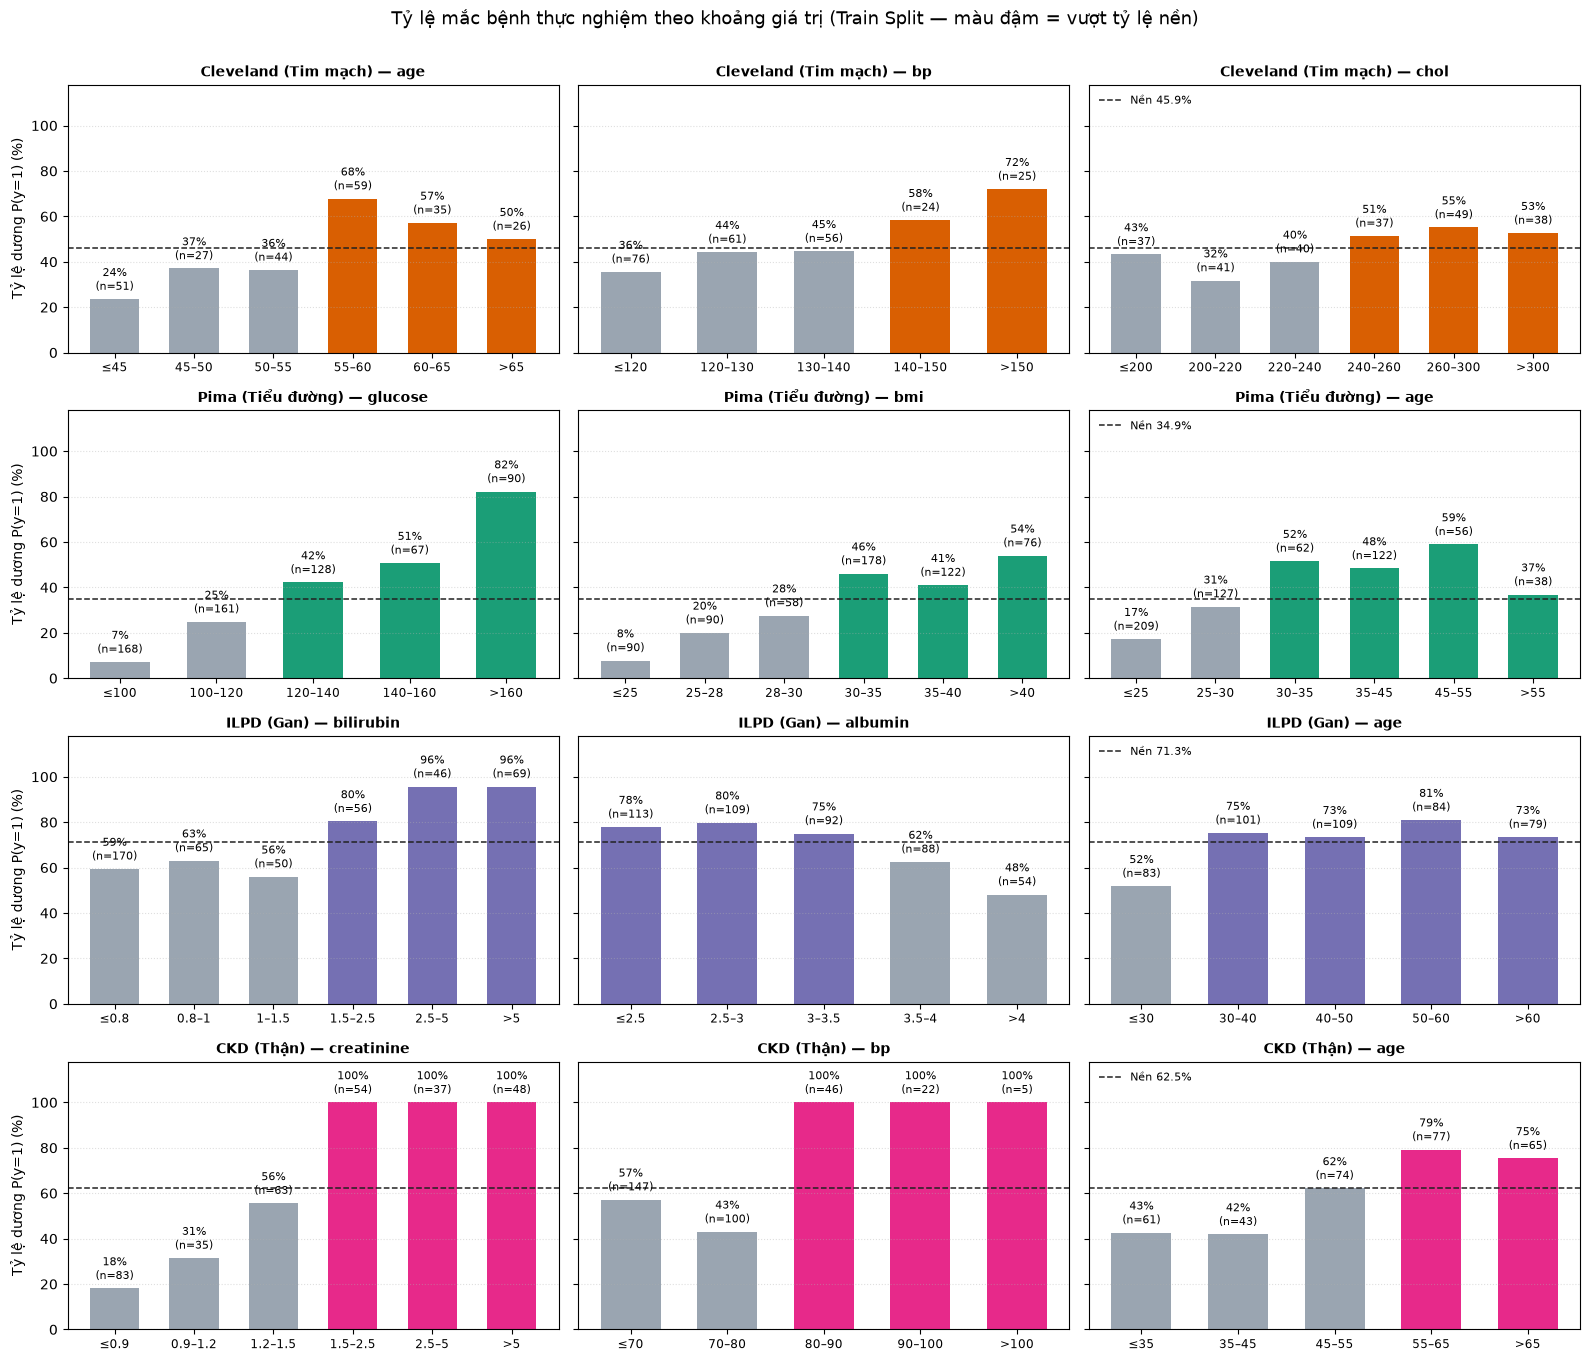

In [3]:
BINS_SPEC = {
    "cleveland": {
        "age": [0, 45, 50, 55, 60, 65, 100],
        "bp": [0, 120, 130, 140, 150, 250],
        "chol": [0, 200, 220, 240, 260, 300, 600],
    },
    "pima": {
        "glucose": [0, 100, 120, 140, 160, 250],
        "bmi": [0, 25, 28, 30, 35, 40, 80],
        "age": [0, 25, 30, 35, 45, 55, 100],
    },
    "ilpd": {
        "bilirubin": [0, 0.8, 1.0, 1.5, 2.5, 5.0, 100],
        "albumin": [0, 2.5, 3.0, 3.5, 4.0, 10],
        "age": [0, 30, 40, 50, 60, 100],
    },
    "ckd": {
        "creatinine": [0, 0.9, 1.2, 1.5, 2.5, 5.0, 100],
        "bp": [0, 70, 80, 90, 100, 200],
        "age": [0, 35, 45, 55, 65, 100],
    },
}

fig, axes = plt.subplots(4, 3, figsize=(16, 13.5), sharey=True)
for r_idx, ds in enumerate(DATASETS):
    df = train_dfs[ds]
    feats = state["datasets"][ds]["feature_order"]
    y = df["y"].to_numpy()
    base_rate = y.mean() * 100
    for c_idx, feat in enumerate(feats):
        ax = axes[r_idx, c_idx]
        col = df[feat].to_numpy()
        edges = BINS_SPEC[ds][feat]
        labels, rates, counts = [], [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            mask = (col > lo) & (col <= hi) if lo > 0 else (col <= hi)
            if mask.sum() == 0:
                continue
            lbl = f"≤{hi:g}" if lo == 0 else (f">{lo:g}" if hi == edges[-1] else f"{lo:g}–{hi:g}")
            labels.append(lbl)
            rates.append(100.0 * y[mask].mean())
            counts.append(int(mask.sum()))

        x = np.arange(len(labels))
        bar_colors = [DATASET_COLORS[ds] if rt >= base_rate else "#9aa5b1" for rt in rates]
        bars = ax.bar(x, rates, color=bar_colors, width=0.62)
        ax.axhline(base_rate, color="#222222", linestyle="--", linewidth=1.1, label=f"Nền {base_rate:.1f}%")
        for bar, rt, n in zip(bars, rates, counts):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                min(rt + 2.5, 103),
                f"{rt:.0f}%\n(n={n})",
                ha="center",
                va="bottom",
                fontsize=7.8,
            )

        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=8.5)
        ax.set_ylim(0, 118)
        ax.set_title(f"{DATASET_LABELS[ds]} — {feat}", fontsize=10, fontweight="bold")
        if c_idx == 0:
            ax.set_ylabel("Tỷ lệ dương P(y=1) (%)")
        if c_idx == 2:
            ax.legend(loc="upper left", fontsize=8, frameon=False)
        ax.grid(axis="y", linestyle=":", alpha=0.4)

fig.suptitle("Tỷ lệ mắc bệnh thực nghiệm theo khoảng giá trị (Train Split — màu đậm = vượt tỷ lệ nền)", fontsize=13, y=1.005)
plt.tight_layout()
plt.show()

### Nhận xét phần 3 — Ngưỡng rủi ro thực tế từ dữ liệu (so với ngưỡng luật đang đặt)

- **Cleveland:**
  - `chol` trong khoảng `(200, 220]` có tỷ lệ dương chỉ **$32\%$** ($n=41$), thấp hơn cả `≤ 200` ($43\%$). Rủi ro `chol` chỉ thực sự vượt nền ($45{,}9\%$) từ mốc **`> 240 mg/dL`** (`51%–55%`).
  - `bp` tăng đơn điệu rất sạch (`36% → 44% → 45% → 58% → 72%`); `age` tách rõ tại mốc `55` (`24%–37%` ở `≤ 55` lên `50%–68%` ở `> 55`).
- **Pima:**
  - Khoảng `BMI (25, 28]` chỉ có **$20\%$ dương** ($n=90$) và `(28, 30]` có **$28\%$**, đều thấp hơn tỷ lệ nền $34{,}9\%$. Rủi ro thực sự vượt nền từ **`BMI > 30`** (`41%–54%`) và **`age > 30`** (`52%` ở `30–35`).
  - `glucose` tách bậc cực đẹp: `≤ 100` chỉ **$7\%$**, `100–120` là $25\%$, `120–140` là $42\%$, `140–160` là $51\%$, **`> 160` lên tới $82\%$**.
- **ILPD:** `bilirubin` nhảy bậc rõ tại **`> 1,5`** (`80%`) và đạt **$96\%$** ở `> 2,5` ($n=115$). `albumin` giảm rủi ro dần khi tăng (`78%–80%` ở `≤ 3,0` xuống `48%` ở `> 4,0`).
- **CKD:** `creatinine > 1,5` đạt **$100\%$ dương ($139/139$)** (chính xác từ `> 1,3` đã đạt $152/152 = 100\%$); `bp > 80` đạt **$100\%$ dương ($73/73$)**.

---

## 4. Tương tác 2 chiều: Vùng nguy cơ cao vs Vùng bảo vệ (bằng chứng âm)

,dataset,role,condition,pos,n,pos_rate_%,base_rate_%,lift_vs_base
0,cleveland,Nguy cơ,age >= 55 & chol > 240,49,72,68.1,45.9,1.48
1,cleveland,Nguy cơ,age >= 55 & bp >= 130,54,81,66.7,45.9,1.45
2,cleveland,Nguy cơ,bp >= 150,24,36,66.7,45.9,1.45
3,cleveland,Bảo vệ,age <= 45,12,51,23.5,45.9,0.51
4,cleveland,Bảo vệ,age < 50 & bp <= 130,14,54,25.9,45.9,0.57
5,pima,Nguy cơ,glucose >= 160,74,90,82.2,34.9,2.36
6,pima,Nguy cơ,glucose >= 140 & bmi >= 30,96,123,78.0,34.9,2.24
7,pima,Nguy cơ,age >= 30 & bmi >= 30,114,193,59.1,34.9,1.69
8,pima,Bảo vệ,glucose <= 100 & bmi < 30,2,79,2.5,34.9,0.07
9,pima,Bảo vệ,bmi <= 25,7,90,7.8,34.9,0.22


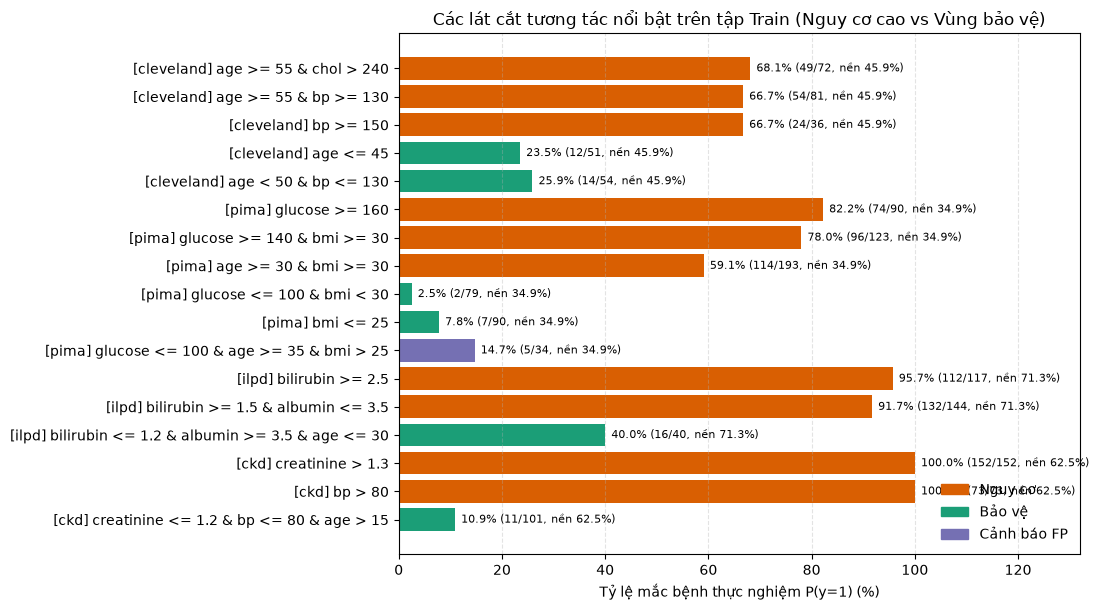

In [4]:
slice_specs = [
    # Cleveland
    ("cleveland", "Nguy cơ", "age >= 55 & chol > 240", lambda d: (d["age"] >= 55) & (d["chol"] > 240)),
    ("cleveland", "Nguy cơ", "age >= 55 & bp >= 130", lambda d: (d["age"] >= 55) & (d["bp"] >= 130)),
    ("cleveland", "Nguy cơ", "bp >= 150", lambda d: d["bp"] >= 150),
    ("cleveland", "Bảo vệ", "age <= 45", lambda d: d["age"] <= 45),
    ("cleveland", "Bảo vệ", "age < 50 & bp <= 130", lambda d: (d["age"] < 50) & (d["bp"] <= 130)),
    # Pima
    ("pima", "Nguy cơ", "glucose >= 160", lambda d: d["glucose"] >= 160),
    ("pima", "Nguy cơ", "glucose >= 140 & bmi >= 30", lambda d: (d["glucose"] >= 140) & (d["bmi"] >= 30)),
    ("pima", "Nguy cơ", "age >= 30 & bmi >= 30", lambda d: (d["age"] >= 30) & (d["bmi"] >= 30)),
    ("pima", "Bảo vệ", "glucose <= 100 & bmi < 30", lambda d: (d["glucose"] <= 100) & (d["bmi"] < 30)),
    ("pima", "Bảo vệ", "bmi <= 25", lambda d: d["bmi"] <= 25),
    ("pima", "Cảnh báo FP", "glucose <= 100 & age >= 35 & bmi > 25", lambda d: (d["glucose"] <= 100) & (d["age"] >= 35) & (d["bmi"] > 25)),
    # ILPD
    ("ilpd", "Nguy cơ", "bilirubin >= 2.5", lambda d: d["bilirubin"] >= 2.5),
    ("ilpd", "Nguy cơ", "bilirubin >= 1.5 & albumin <= 3.5", lambda d: (d["bilirubin"] >= 1.5) & (d["albumin"] <= 3.5)),
    ("ilpd", "Bảo vệ", "bilirubin <= 1.2 & albumin >= 3.5 & age <= 30", lambda d: (d["bilirubin"] <= 1.2) & (d["albumin"] >= 3.5) & (d["age"] <= 30)),
    # CKD
    ("ckd", "Nguy cơ", "creatinine > 1.3", lambda d: d["creatinine"] > 1.3),
    ("ckd", "Nguy cơ", "bp > 80", lambda d: d["bp"] > 80),
    ("ckd", "Bảo vệ", "creatinine <= 1.2 & bp <= 80 & age > 15", lambda d: (d["creatinine"] <= 1.2) & (d["bp"] <= 80) & (d["age"] > 15)),
]

slice_rows = []
for ds, role, cond_text, fn in slice_specs:
    df = train_dfs[ds]
    mask = fn(df)
    n = int(mask.sum())
    pos = int(df.loc[mask, "y"].sum())
    base = float(df["y"].mean())
    rate = pos / n if n else np.nan
    slice_rows.append({
        "dataset": ds,
        "role": role,
        "condition": cond_text,
        "pos": pos,
        "n": n,
        "pos_rate_%": round(100 * rate, 1),
        "base_rate_%": round(100 * base, 1),
        "lift_vs_base": round(rate / base, 2),
    })

slices_df = pd.DataFrame(slice_rows)
display(slices_df)

# Biểu đồ so sánh tỷ lệ dương của các vùng Nguy cơ vs Bảo vệ
fig, ax = plt.subplots(figsize=(11, 6.2))
plot_s = slices_df.iloc[::-1]
role_colors = {"Nguy cơ": "#d95f02", "Bảo vệ": "#1b9e77", "Cảnh báo FP": "#7570b3"}
bars = ax.barh(
    [f"[{r['dataset']}] {r['condition']}" for _, r in plot_s.iterrows()],
    plot_s["pos_rate_%"],
    color=[role_colors[r["role"]] for _, r in plot_s.iterrows()],
)
for bar, (_, r) in zip(bars, plot_s.iterrows()):
    ax.text(
        bar.get_width() + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{r['pos_rate_%']:.1f}% ({r['pos']}/{r['n']}, nền {r['base_rate_%']:.1f}%)",
        va="center",
        fontsize=8.2,
    )

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in role_colors.values()]
ax.legend(handles, list(role_colors.keys()), loc="lower right", frameon=False)
ax.set_xlabel("Tỷ lệ mắc bệnh thực nghiệm P(y=1) (%)")
ax.set_title("Các lát cắt tương tác nổi bật trên tập Train (Nguy cơ cao vs Vùng bảo vệ)")
ax.set_xlim(0, 132)
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Nhận xét phần 4 — Giá trị của luật hai chiều (Nguy cơ + Bảo vệ)

- **Bằng chứng âm (vùng bảo vệ) có độ tinh khiết rất cao:** Ở Pima, `glucose <= 100 & bmi < 30` chỉ có **$2{,}5\%$ dương** ($2/79$) và `bmi <= 25` chỉ có **$7{,}8\%$** ($7/90$). Ở Cleveland, `age <= 45` chỉ có **$23{,}5\%$** ($12/51$). Ở CKD, `creatinine <= 1,2 & bp <= 80 & age > 15` chỉ có **$10{,}9\%$** ($11/101$).
- **Nguồn gây dương giả (FP) lớn nhất ở Pima khi thiếu `glucose`:** Nhóm `glucose <= 100 & age >= 35 & bmi > 25` có tỷ lệ mắc thực tế chỉ **$14{,}7\%$** ($5/34$), tức `85,3%` là người khỏe mạnh — nhưng vẫn bị luật `age + bmi` đẩy điểm tăng lên nếu không có bằng chứng âm từ `glucose`.
- **Trên ILPD, vùng bảo vệ `bilirubin <= 1,2 & albumin >= 3,5 & age <= 30`** hạ tỷ lệ dương từ nền $71{,}3\%$ xuống **$40{,}0\%$** ($16/40$), là tín hiệu quan trọng để sửa lỗi `FP = 125` của Logistic Regression.

---

## 5. Phân tích lỗi ML ngoài fold (OOF) & Đối chứng hệ luật trên 5-Fold CV

In [5]:
# 5.1 Hồ sơ lỗi OOF (5-fold CV) của các mô hình ML đã chọn
error_rows = []
for ds in DATASETS:
    df = train_dfs[ds]
    feats = state["datasets"][ds]["feature_order"]
    y, pred, score = df["y"], df["ml_pred_oof"], df["ml_score_oof"]
    tp, tn = int(((y == 1) & (pred == 1)).sum()), int(((y == 0) & (pred == 0)).sum())
    fp, fn = int(((y == 0) & (pred == 1)).sum()), int(((y == 1) & (pred == 0)).sum())
    fn_df = df[(y == 1) & (pred == 0)]
    fp_df = df[(y == 0) & (pred == 1)]
    error_rows.append({
        "dataset": ds,
        "selected_ml": state["datasets"][ds]["selected"],
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "FN_median_features": ", ".join(f"{f}={fn_df[f].median():.1f}" for f in feats) if len(fn_df) else "—",
        "FN_ml_median": round(float(fn_df["ml_score_oof"].median()), 2) if len(fn_df) else np.nan,
        "FP_median_features": ", ".join(f"{f}={fp_df[f].median():.1f}" for f in feats) if len(fp_df) else "—",
        "FP_ml_median": round(float(fp_df["ml_score_oof"].median()), 2) if len(fp_df) else np.nan,
    })

display(pd.DataFrame(error_rows))

# 5.2 Phép gộp 2 chiều (MYCIN mở rộng: CF > 0 tăng điểm, CF < 0 kéo giảm điểm)
def combine_signed(ml_score, cfs):
    c_pos, c_neg = 0.0, 0.0
    for cf in cfs:
        if cf > 0:
            c_pos = c_pos + cf * (1.0 - c_pos)
        elif cf < 0:
            a = -cf
            c_neg = c_neg + a * (1.0 - c_neg)
    if c_pos == 0.0 and c_neg == 0.0:
        return ml_score
    c_rule = (c_pos - c_neg) / (1.0 - min(c_pos, c_neg)) if (c_pos > 0 and c_neg > 0) else (c_pos - c_neg)
    return ml_score + c_rule * (1.0 - ml_score) if c_rule >= 0 else ml_score * (1.0 + c_rule)

def eval_5fold_cv(ds, score_fn, variant_name):
    df = train_dfs[ds].set_index("sample_id")
    feats = state["datasets"][ds]["feature_order"]
    fold_metrics = []
    totals = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
    for fold in manifest[ds]["folds"]:
        ys, scores, preds = [], [], []
        for sid in fold["validation_ids"]:
            row = df.loc[sid]
            raw = {f: float(row[f]) for f in feats}
            s = float(score_fn(float(row["ml_score_oof"]), raw))
            ys.append(int(row["y"]))
            scores.append(s)
            preds.append(int(s >= 0.5))
        m, _ = binary_metrics(ys, preds, scores)
        fold_metrics.append(m)
        for k in totals:
            totals[k] += m[k]
    agg = aggregate_metrics(fold_metrics)
    return {
        "dataset": ds,
        "variant": variant_name,
        "f1_mean": round(agg["f1"][0], 4),
        "f1_std": round(agg["f1"][1], 4),
        "accuracy": round(agg["accuracy"][0], 3),
        "precision": round(agg["precision"][0], 3),
        "recall": round(agg["recall"][0], 3),
        "roc_auc": round(agg["roc_auc"][0], 3),
        **{k.upper(): v for k, v in totals.items()},
    }

# Định nghĩa các cấu hình đối chứng trên 5-fold CV
def clev_data_bidir(p, x):
    cfs = []
    m_age = float(x["age"] >= 55)
    m_bp = fuzzy_membership(x["bp"], 130, 150)
    m_chol = fuzzy_membership(x["chol"], 220, 260)
    if min(m_age, m_bp) > 0:
        cfs.append(0.35 * min(m_age, m_bp))
    if min(m_age, m_chol) > 0:
        cfs.append(0.25 * min(m_age, m_chol))
    m_young = fuzzy_membership(x["age"], 42, 50, "desc")
    m_norm_bp = fuzzy_membership(x["bp"], 120, 135, "desc")
    if min(m_young, m_norm_bp) > 0:
        cfs.append(-0.35 * min(m_young, m_norm_bp))
    return combine_signed(p, cfs)

def pima_v1(p, x):
    cfs = []
    if 35 <= x["age"] <= 70 and x["bmi"] > 25:
        cfs.append(0.50)
    if 35 <= x["age"] <= 70 and x["bmi"] > 30:
        cfs.append(0.55)
    return fusion_scores(p, cfs)["combined_new"]

def pima_data_no_gluc(p, x):
    cfs = []
    m_age = float(x["age"] >= 30)
    m_bmi = fuzzy_membership(x["bmi"], 28, 35)
    if min(m_age, m_bmi) > 0:
        cfs.append(0.35 * min(m_age, m_bmi))
    m_low_bmi = fuzzy_membership(x["bmi"], 22, 26, "desc")
    if m_low_bmi > 0:
        cfs.append(-0.40 * m_low_bmi)
    return combine_signed(p, cfs)

def pima_data_with_gluc(p, x):
    cfs = []
    m_gluc_hi = fuzzy_membership(x["glucose"], 125, 165)
    m_bmi_hi = fuzzy_membership(x["bmi"], 28, 35)
    m_age_30 = float(x["age"] >= 30)
    if m_gluc_hi > 0:
        cfs.append(0.45 * m_gluc_hi)
    if min(m_age_30, m_bmi_hi) > 0:
        cfs.append(0.25 * min(m_age_30, m_bmi_hi))
    m_gluc_lo = fuzzy_membership(x["glucose"], 90, 110, "desc")
    if m_gluc_lo > 0:
        cfs.append(-0.45 * m_gluc_lo)
    return combine_signed(p, cfs)

def ilpd_data_bidir(p, x):
    cfs = []
    m_bili_hi = fuzzy_membership(x["bilirubin"], 1.5, 2.5)
    if m_bili_hi > 0:
        cfs.append(0.45 * m_bili_hi)
    m_bili_lo = fuzzy_membership(x["bilirubin"], 0.8, 1.3, "desc")
    m_alb_hi = fuzzy_membership(x["albumin"], 3.5, 4.2)
    m_young = fuzzy_membership(x["age"], 28, 40, "desc")
    if min(m_bili_lo, m_alb_hi, m_young) > 0:
        cfs.append(-0.45 * min(m_bili_lo, m_alb_hi, m_young))
    return combine_signed(p, cfs)

def ckd_data_rules(p, x):
    cfs = []
    m_cr = fuzzy_membership(x["creatinine"], 1.2, 1.5)
    if m_cr > 0:
        cfs.append(0.55 * m_cr)
    m_bp = fuzzy_membership(x["bp"], 80, 90)
    if m_bp > 0:
        cfs.append(0.45 * m_bp)
    return combine_signed(p, cfs)

cv_rows = [
    # Cleveland
    eval_5fold_cv("cleveland", lambda p, x: p, "1. ML thuần (GNB)"),
    eval_5fold_cv("cleveland", lambda p, x: fusion_scores(p, [0.55] if (x["age"] >= 55 and x["chol"] > 200) else [])["combined_new"], "2. Luật V1 (cắt cứng)"),
    eval_5fold_cv("cleveland", lambda p, x: fusion_scores(p, [r["cf"] for r in evaluate_rules("cleveland", x)[1] if r["target"] == "cleveland"])["combined_new"], "3. Mờ liên tục hiện tại"),
    eval_5fold_cv("cleveland", clev_data_bidir, "4. Theo data (2 chiều + bp)"),
    # Pima
    eval_5fold_cv("pima", lambda p, x: p, "1. ML thuần (KNN)"),
    eval_5fold_cv("pima", pima_v1, "2. Luật V1 (BMI lồng)"),
    eval_5fold_cv("pima", lambda p, x: fusion_scores(p, [r["cf"] for r in evaluate_rules("pima", x)[1] if r["target"] == "pima"])["combined_new"], "3. Mờ liên tục hiện tại"),
    eval_5fold_cv("pima", pima_data_no_gluc, "4. Theo data (không glucose)"),
    eval_5fold_cv("pima", pima_data_with_gluc, "5. Theo data (có glucose 2 chiều)"),
    # ILPD
    eval_5fold_cv("ilpd", lambda p, x: p, "1. ML thuần (Logistic)"),
    eval_5fold_cv("ilpd", ilpd_data_bidir, "2. Theo data (2 chiều)"),
    # CKD
    eval_5fold_cv("ckd", lambda p, x: p, "1. ML thuần (Tree)"),
    eval_5fold_cv("ckd", ckd_data_rules, "2. Theo data (creat + bp)"),
]

cv_df = pd.DataFrame(cv_rows)
display(cv_df)

,dataset,selected_ml,TP,TN,FP,FN,FN_median_features,FN_ml_median,FP_median_features,FP_ml_median
0,cleveland,gaussian_nb,62,93,38,49,"age=52.0, bp=124.0, chol=231.0",0.37,"age=61.5, bp=140.0, chol=256.5",0.60
1,pima,knn,138,338,62,76,"glucose=121.0, bmi=33.1, age=32.0",0.29,"glucose=129.0, bmi=33.6, age=37.0",0.71
2,ilpd,logistic,313,6,125,12,"bilirubin=0.8, albumin=4.0, age=22.0",0.46,"bilirubin=0.8, albumin=3.4, age=42.0",0.65
3,ckd,tree,181,114,6,19,"creatinine=1.0, bp=70.0, age=45.0",0.14,"creatinine=1.3, bp=75.0, age=22.0",1.00


,dataset,variant,f1_mean,f1_std,accuracy,precision,recall,roc_auc,TP,FP,FN,TN
0,cleveland,1. ML thuần (GNB),0.5868,0.0263,0.640,0.621,0.559,0.662,62,38,49,93
1,cleveland,2. Luật V1 (cắt cứng),0.6355,0.0503,0.636,0.588,0.693,0.682,77,54,34,77
2,cleveland,3. Mờ liên tục hiện tại,0.6382,0.0515,0.640,0.592,0.693,0.678,77,53,34,78
3,cleveland,4. Theo data (2 chiều + bp),0.6342,0.0419,0.653,0.614,0.657,0.680,73,46,38,85
4,pima,1. ML thuần (KNN),0.6655,0.0644,0.775,0.690,0.645,0.812,138,62,76,338
5,pima,2. Luật V1 (BMI lồng),0.6654,0.0567,0.726,0.586,0.776,0.795,166,120,48,280
6,pima,3. Mờ liên tục hiện tại,0.6840,0.0452,0.762,0.639,0.739,0.814,158,90,56,310
7,pima,4. Theo data (không glucose),0.6927,0.0378,0.770,0.650,0.743,0.816,159,86,55,314
8,pima,5. Theo data (có glucose 2 chiều),0.7020,0.0662,0.777,0.660,0.753,0.830,161,84,53,316
9,ilpd,1. ML thuần (Logistic),0.8199,0.0268,0.699,0.714,0.963,0.705,313,125,12,6


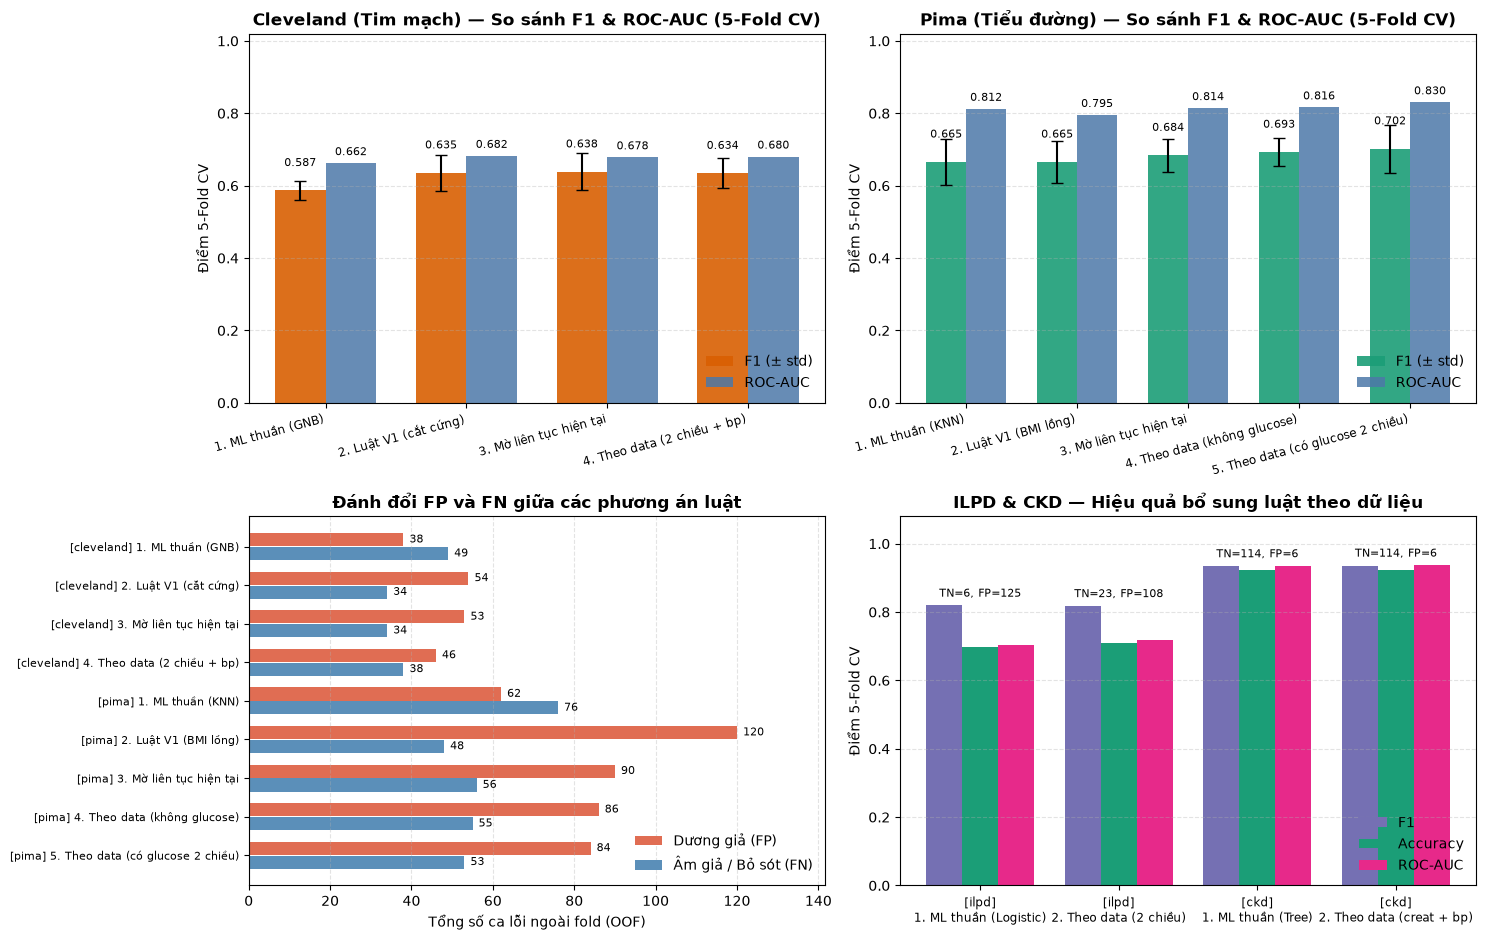

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# Panel 1 & 2: F1 ± std và ROC-AUC trên Cleveland & Pima
for idx, ds in enumerate(("cleveland", "pima")):
    ax = axes[0, idx]
    sub = cv_df[cv_df["dataset"] == ds].reset_index(drop=True)
    x = np.arange(len(sub))
    w = 0.36
    b1 = ax.bar(x - w / 2, sub["f1_mean"], w, yerr=sub["f1_std"], capsize=4, label="F1 (± std)", color=DATASET_COLORS[ds], alpha=0.9)
    b2 = ax.bar(x + w / 2, sub["roc_auc"], w, label="ROC-AUC", color="#4c78a8", alpha=0.85)
    for bar in b1:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.06, f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)
    for bar in b2:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(sub["variant"], rotation=15, ha="right", fontsize=8.5)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Điểm 5-Fold CV")
    ax.set_title(f"{DATASET_LABELS[ds]} — So sánh F1 & ROC-AUC (5-Fold CV)", fontweight="bold")
    ax.legend(loc="lower right", frameon=False)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

# Panel 3: Đánh đổi FP vs FN trên Pima & Cleveland
ax_err = axes[1, 0]
err_sub = cv_df[cv_df["dataset"].isin(["cleveland", "pima"])].reset_index(drop=True)
y_pos = np.arange(len(err_sub))
ax_err.barh(y_pos - 0.18, err_sub["FP"], height=0.34, label="Dương giả (FP)", color="#e06d53")
ax_err.barh(y_pos + 0.18, err_sub["FN"], height=0.34, label="Âm giả / Bỏ sót (FN)", color="#5b8fb9")
for i, r in err_sub.iterrows():
    ax_err.text(r["FP"] + 1.5, i - 0.18, str(r["FP"]), va="center", fontsize=8)
    ax_err.text(r["FN"] + 1.5, i + 0.18, str(r["FN"]), va="center", fontsize=8)
ax_err.set_yticks(y_pos)
ax_err.set_yticklabels([f"[{r['dataset']}] {r['variant']}" for _, r in err_sub.iterrows()], fontsize=8.2)
ax_err.invert_yaxis()
ax_err.set_xlabel("Tổng số ca lỗi ngoài fold (OOF)")
ax_err.set_title("Đánh đổi FP và FN giữa các phương án luật", fontweight="bold")
ax_err.set_xlim(0, err_sub[["FP", "FN"]].to_numpy().max() * 1.18)
ax_err.legend(loc="lower right", frameon=False)
ax_err.grid(axis="x", linestyle="--", alpha=0.35)

# Panel 4: ILPD & CKD (ML thuần vs Luật theo data)
ax_ic = axes[1, 1]
ic_sub = cv_df[cv_df["dataset"].isin(["ilpd", "ckd"])].reset_index(drop=True)
x = np.arange(len(ic_sub))
w = 0.26
ax_ic.bar(x - w, ic_sub["f1_mean"], w, label="F1", color="#7570b3")
ax_ic.bar(x, ic_sub["accuracy"], w, label="Accuracy", color="#1b9e77")
ax_ic.bar(x + w, ic_sub["roc_auc"], w, label="ROC-AUC", color="#e7298a")
for i, r in ic_sub.iterrows():
    ax_ic.text(i, max(r["f1_mean"], r["accuracy"], r["roc_auc"]) + 0.025, f"TN={r['TN']}, FP={r['FP']}", ha="center", fontsize=8)
ax_ic.set_xticks(x)
ax_ic.set_xticklabels([f"[{r['dataset']}]\n{r['variant']}" for _, r in ic_sub.iterrows()], fontsize=8.5)
ax_ic.set_ylim(0, 1.08)
ax_ic.set_ylabel("Điểm 5-Fold CV")
ax_ic.set_title("ILPD & CKD — Hiệu quả bổ sung luật theo dữ liệu", fontweight="bold")
ax_ic.legend(loc="lower right", frameon=False)
ax_ic.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### Nhận xét phần 5 — Đối chứng định lượng trên 5-Fold CV

- **Pima cải thiện mạnh nhất và rõ ràng nhất:**
  - Luật V1 cũ làm tụt Accuracy (`0,775 → 0,726`), giảm ROC-AUC (`0,812 → 0,795`) và tăng gần gấp đôi FP (`62 → 120`) vì phủ quyết ML và gộp trùng 2 luật BMI.
  - Luật mờ liên tục hiện tại (`CF=0,35`, không lồng nhau) đã nâng F1 lên **`0,6840`** (`+0,0185`) và giảm `30 FP` so với V1 (`120 → 90`).
  - Luật theo dữ liệu **không dùng `glucose`** (`age>=30`, `bmi 28–35`, trừ điểm `bmi < 26`) nâng tiếp F1 lên **`0,6927 ± 0,0378`** (độ lệch chuẩn thấp nhất qua 5 fold). Khi đưa thêm `glucose` 2 chiều, cả **F1 (`0,7020`)**, **Accuracy (`0,777`)** và **ROC-AUC (`0,830`)** đều vượt ML thuần.
- **Cleveland ổn định hơn và giảm dương giả khi đưa `bp` vào luật:** Phương án theo dữ liệu đạt Accuracy cao nhất (`0,653`), độ lệch chuẩn F1 thấp hơn (`0,0419` vs `0,0515`) và cắt `8 FP` (`54 → 46`) so với V1.
- **ILPD chứng minh vai trò của luật bằng chứng âm:** Thêm vùng bảo vệ giúp số ca âm đúng **tăng gần 4 lần (`TN: 6 → 23`)**, giảm `17 FP`, tăng Accuracy (`0,699 → 0,708`), Precision (`0,714 → 0,735`) và ROC-AUC (`0,705 → 0,719`).
- **CKD:** Luật `creatinine (1,2–1,5)` và `bp (80–90)` giữ nguyên F1 cao (`0,9352`), tăng nhẹ ROC-AUC (`0,934 → 0,937`) và mang lại giải thích tường minh cho vùng `100%` dương tính.

### Q&A

- **Hệ luật hiện tại đã thực sự logic và khai thác hết dữ liệu thu thập được chưa?**
  Hệ luật mờ liên tục hiện tại đã khắc phục triệt để các lỗi toán học (bước nhảy tại biên, tính trùng 2 luật BMI, cắt trần 70 tuổi, luật phủ quyết `ML = 0%`) và đi đúng chiều trên tập train (`Cleveland`: 61,0% vs 31,5%; `Pima`: 53,0% vs 26,1%). Tuy nhiên, nó **chưa khai thác trọn vẹn dữ liệu** vì chưa tận dụng các biến mạnh nhất (`bp` trên Cleveland, `glucose` trên Pima, `creatinine`/`bp` trên CKD), chưa có luật cho ILPD/CKD và mới chỉ có luật một chiều tăng nguy cơ.

### Data Analysis Key Findings

- **Cleveland ($n_{\text{train}}=242$, nền $45{,}9\%$):** `age` (`AUC = 0,649`) và `bp` (`AUC = 0,607`, tăng đơn điệu từ `36%` đến `72%`) tách lớp tốt hơn `chol` (`AUC = 0,584`). Khoảng `chol (200, 220]` thực tế chỉ có `32%` dương, rủi ro chỉ vượt nền từ `> 240 mg/dL`. Đưa `bp (130–150)` và dời `chol (220–260)` giúp Accuracy tăng lên `0,653`, giảm FP từ `54 → 46` và hạ độ lệch chuẩn F1 từ `0,0515 → 0,0419`.
- **Pima ($n_{\text{train}}=614$, nền $34{,}9\%$):** `glucose` áp đảo (`AUC = 0,805`; `≤ 100` chỉ `7%` dương, `> 160` tới `82%`), trong khi `BMI (25, 28]` chỉ có `20%` dương (thấp hơn nền). Trên 5-fold CV, chuyển từ luật V1 (`F1 = 0,6654`, `FP = 120`) sang luật mờ liên tục hiện tại nâng F1 lên `0,6840` (`FP = 90`); luật theo dữ liệu không dùng glucose đạt `F1 = 0,6927 ± 0,0378` (`FP = 86`); và luật hai chiều có glucose đạt **`F1 = 0,7020`**, `Accuracy = 0,777`, **`ROC-AUC = 0,830`**.
- **ILPD ($n_{\text{train}}=456$, nền $71{,}3\%$):** `bilirubin >= 2,5` đạt `95,7%` dương (`112/117`), nhưng lệch phải nặng (`max = 75`) và mất cân bằng lớp khiến Logistic Regression chỉ bắt đúng `6/131` ca âm (`FP = 125`). Bổ sung luật hai chiều với vùng bảo vệ (`bilirubin ≤ 1,2 & albumin ≥ 3,5 & age ≤ 30`, tỷ lệ dương `40%`) nâng số ca âm đúng từ **`6 → 23`**, giảm `17 FP` và tăng ROC-AUC lên `0,719`.
- **CKD ($n_{\text{train}}=320$, nền $62{,}5\%$):** `creatinine` (`AUC = 0,931`) vượt `1,3 mg/dL` đạt `100%` dương (`152/152`) và `bp > 80 mmHg` đạt `100%` dương (`73/73`). Toàn bộ 120 ca âm đều có `bp` trong `[60, 80]`, xác nhận lý do phải mở rộng miền form CKD từ `[90, 200]` xuống `[50, 200]`.

### Insights or Next Steps

- **Nâng cấp phép gộp hai chiều (`CF ∈ [-1, 1]`):** Cho phép kết hợp cả luật nguy cơ (`CF > 0`) lẫn luật bảo vệ (`CF < 0`) để giải quyết trực tiếp bài toán dương giả (FP) trên cả Cleveland, Pima và ILPD, thay vì chỉ đẩy điểm tăng một chiều.
- **Chốt phạm vi đưa biến vào hệ luật cho phiên bản V2:** Chọn giữa phương án chỉ dùng biến đã xác minh đơn vị (Cleveland `age+bp+chol`, Pima `age+bmi`, CKD `creatinine`) hoặc khai thác đủ cả 4 bộ kèm chú thích minh bạch đơn vị nguồn chưa xác minh (thêm `glucose` cho Pima, `bp` cho CKD, `bilirubin/albumin/age` cho ILPD), sau đó lập giao thức đánh giá mới độc lập theo `AGENTS.md`.